# RQ2: controlled-action states and integrated timeline

The selected original plotting style, explicit input labels and original P03 display are retained. This notebook shows the controlled actions, the seven-phase room timeline and its phase summary.

Run notebook 03 first only if regenerating the results. Sequential fan duties start from different CO₂ concentrations and do not establish a causal duty ranking. See `DATA_NOTES.md` for source details and interpretation.

Saved results and plots are included below; no rerun is needed to inspect them. Regeneration is optional.

In [1]:
from pathlib import Path
import sys

REPO_ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                  if (p / "notebooks").is_dir() and (p / "src" / "indoortwin" / "paths.py").is_file()), None)
if REPO_ROOT is None:
    raise FileNotFoundError("Open this notebook from inside the repository.")
sys.path.insert(0, str(REPO_ROOT / "src"))
from indoortwin import rq2_timeline as timeline
from IPython.display import Image, display

for directory in (timeline.FIGURE_DIR, timeline.TABLE_DIR):
    directory.mkdir(parents=True, exist_ok=True)
trajectory, transitions, events = timeline.load_inputs()
origin = trajectory["sample_time"].iloc[0]
trajectory["minute"] = timeline.minutes_from(trajectory["sample_time"], origin)
phases = timeline.phase_windows(events, origin)
summary = timeline.phase_summary(trajectory)
assert len(trajectory) == 1140 and len(phases) == 7
assert trajectory.co2_indoor_ppm.max() == 796
figure = timeline.FIGURE_DIR / "figure_rq2_integrated_timeline.png"
step_figure = timeline.FIGURE_DIR / "figure_rq2_calculated_states.png"
timeline.plot_integrated_timeline(trajectory, transitions, phases, summary, figure.with_suffix(""))
states = timeline.load_table53()
timeline.plot_table53(states, step_figure)
states.to_csv(timeline.TABLE_DIR / "rq2_step_states.csv", index=False)
summary.to_csv(timeline.TABLE_DIR / "table_5_3_phase_summary.csv", index=False)
result = {"figure": str(figure), "table53_figure": str(step_figure), "steps": states}
print(f"Experiment: {timeline.EXPERIMENT_ID}")
print(f"Trajectory rows: {len(trajectory)}; logged phases: {len(phases)}")
print("Controlled-action plot:", step_figure)
print("Integrated timeline:", figure)


Experiment: EXP_RQ2_CO2_V11_20261004_211358
Trajectory rows: 1140; logged phases: 7
Controlled-action plot: C:\Users\AMN\Downloads\~COMP971~\tmp\Examiner evidence verification\results\rq2_timeline\figures\figure_rq2_calculated_states.png
Integrated timeline: C:\Users\AMN\Downloads\~COMP971~\tmp\Examiner evidence verification\results\rq2_timeline\figures\figure_rq2_integrated_timeline.png


## Phase summary

Endpoint slope is (end − start) / elapsed minutes. Display bands meet at the midpoint of setup gaps; original logged start/end times are retained in the phase summary.

In [2]:
display_columns = [
    "phase_name",
    "rows",
    "observed_min",
    "duty_percent",
    "mean_exh_rpm",
    "co2_start_ppm",
    "co2_end_ppm",
    "slope_ppm_per_min",
    "primary_derived_state",
]
display(summary[display_columns])

,phase_name,rows,observed_min,duty_percent,mean_exh_rpm,co2_start_ppm,co2_end_ppm,slope_ppm_per_min,primary_derived_state
0,Unoccupied baseline,120,9.9,0,0,536,544,0.81,Unoccupied; ventilation off; all closed; CO2 n...
1,CO₂ accumulation,360,29.9,0,0,544,789,8.18,Occupied; ventilation off; one 5 s occupancy r...
2,Fan duty cycle 60%,120,9.9,60,1883,789,625,-16.53,All three fans running after measured RPM cros...
3,Fan duty cycle 80%,120,9.9,80,2405,624,497,-12.80,All-running state retained
4,Fan duty cycle 100%,120,9.9,100,2844,495,465,-3.02,All-running state retained; thermal state retu...
5,Window open,120,9.9,80,2413,464,455,-0.91,Opening present; all-running state retained
6,CO₂ recovery,180,14.9,80,2403,445,405,-2.68,Unoccupied after a 25 s door change; all closed


## Integrated timeline

The original four-panel style is retained. The 800 ppm line is a protocol reference: accumulation ended at the planned duration, and the recorded transition was not triggered by crossing that line. The CO₂ state stayed normal throughout the record.

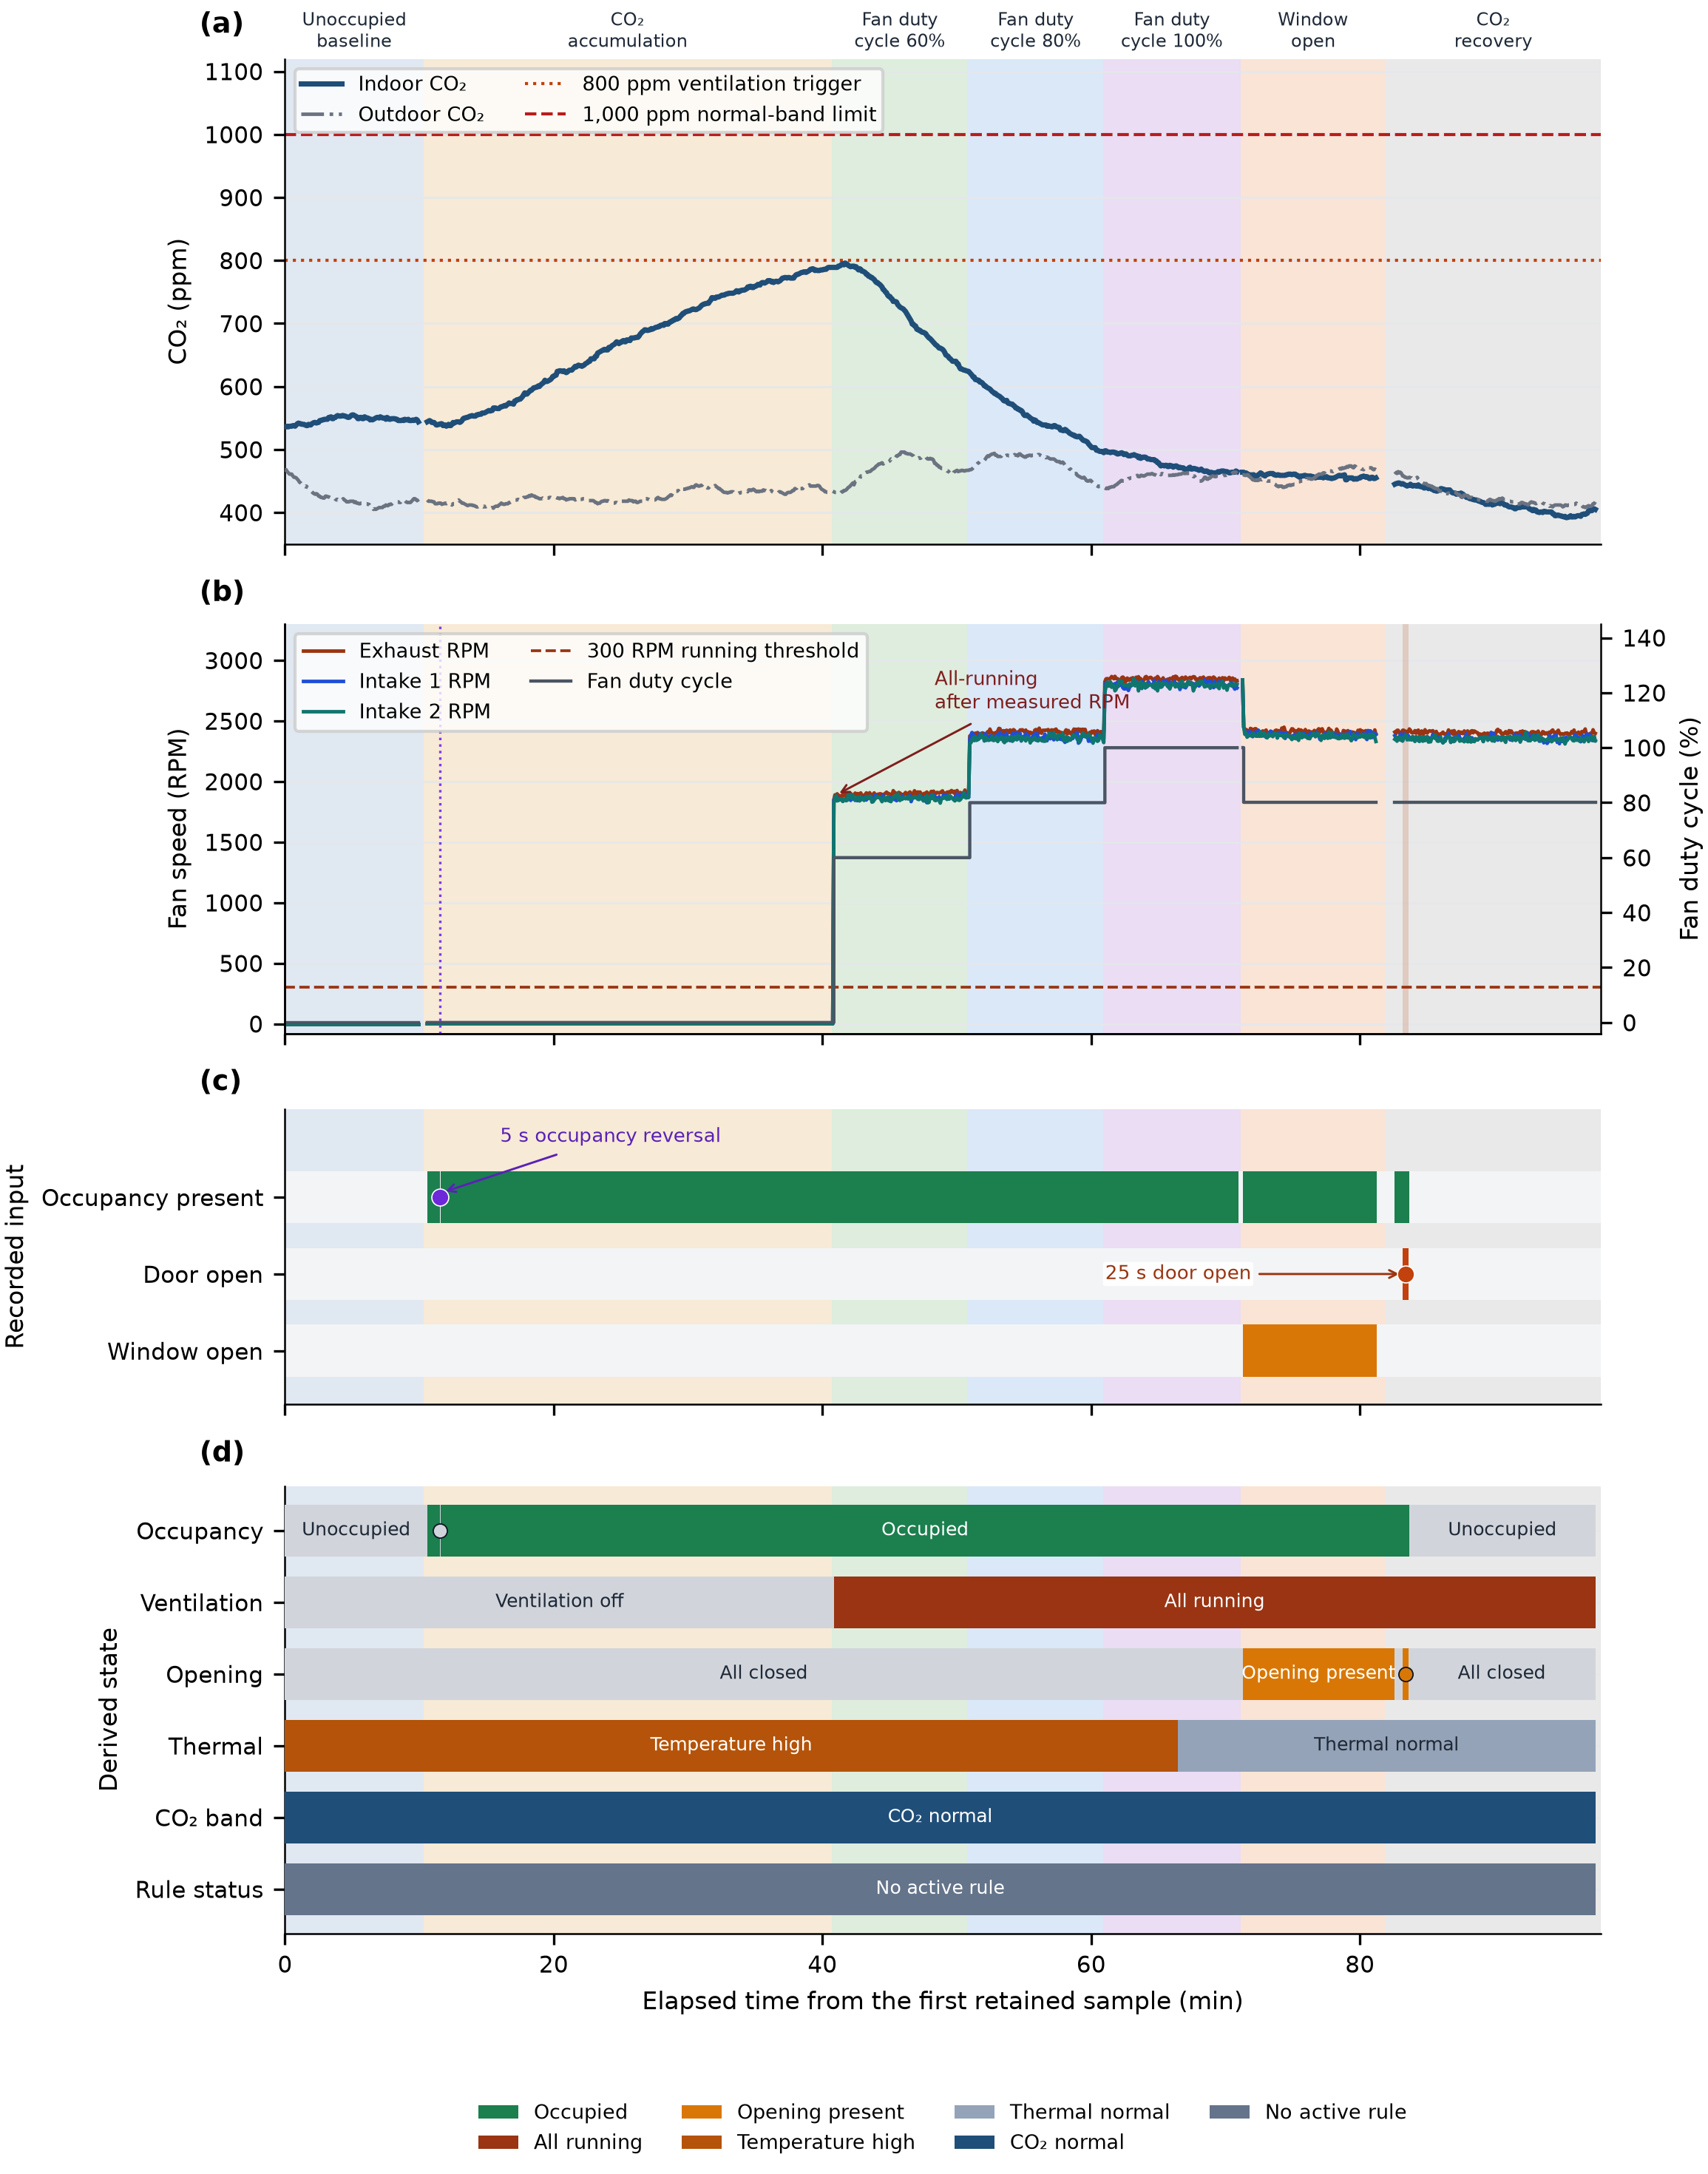

In [3]:
display(Image(filename=result["figure"]))

## Controlled physical actions

The original latency panel, fan readings, explicitly labelled inputs and eight derived-state rows are retained. Outlined cells identify the assessed properties.

P03 uses the successful separate retest for fan readings, ventilation result and recorded 2,018 ms interval. Its other contextual cells come from the earlier pilot snapshot and are not simultaneous observations from the retest. The original unsuccessful attempt remains in the pilot data. Contextual ventilation/health states in P06–P10 are separate from those steps’ assessed opening, heater or occupancy properties.

The timing panel retains the recorded whole-millisecond host intervals; these do not isolate processor, transport or sensor-to-screen latency.

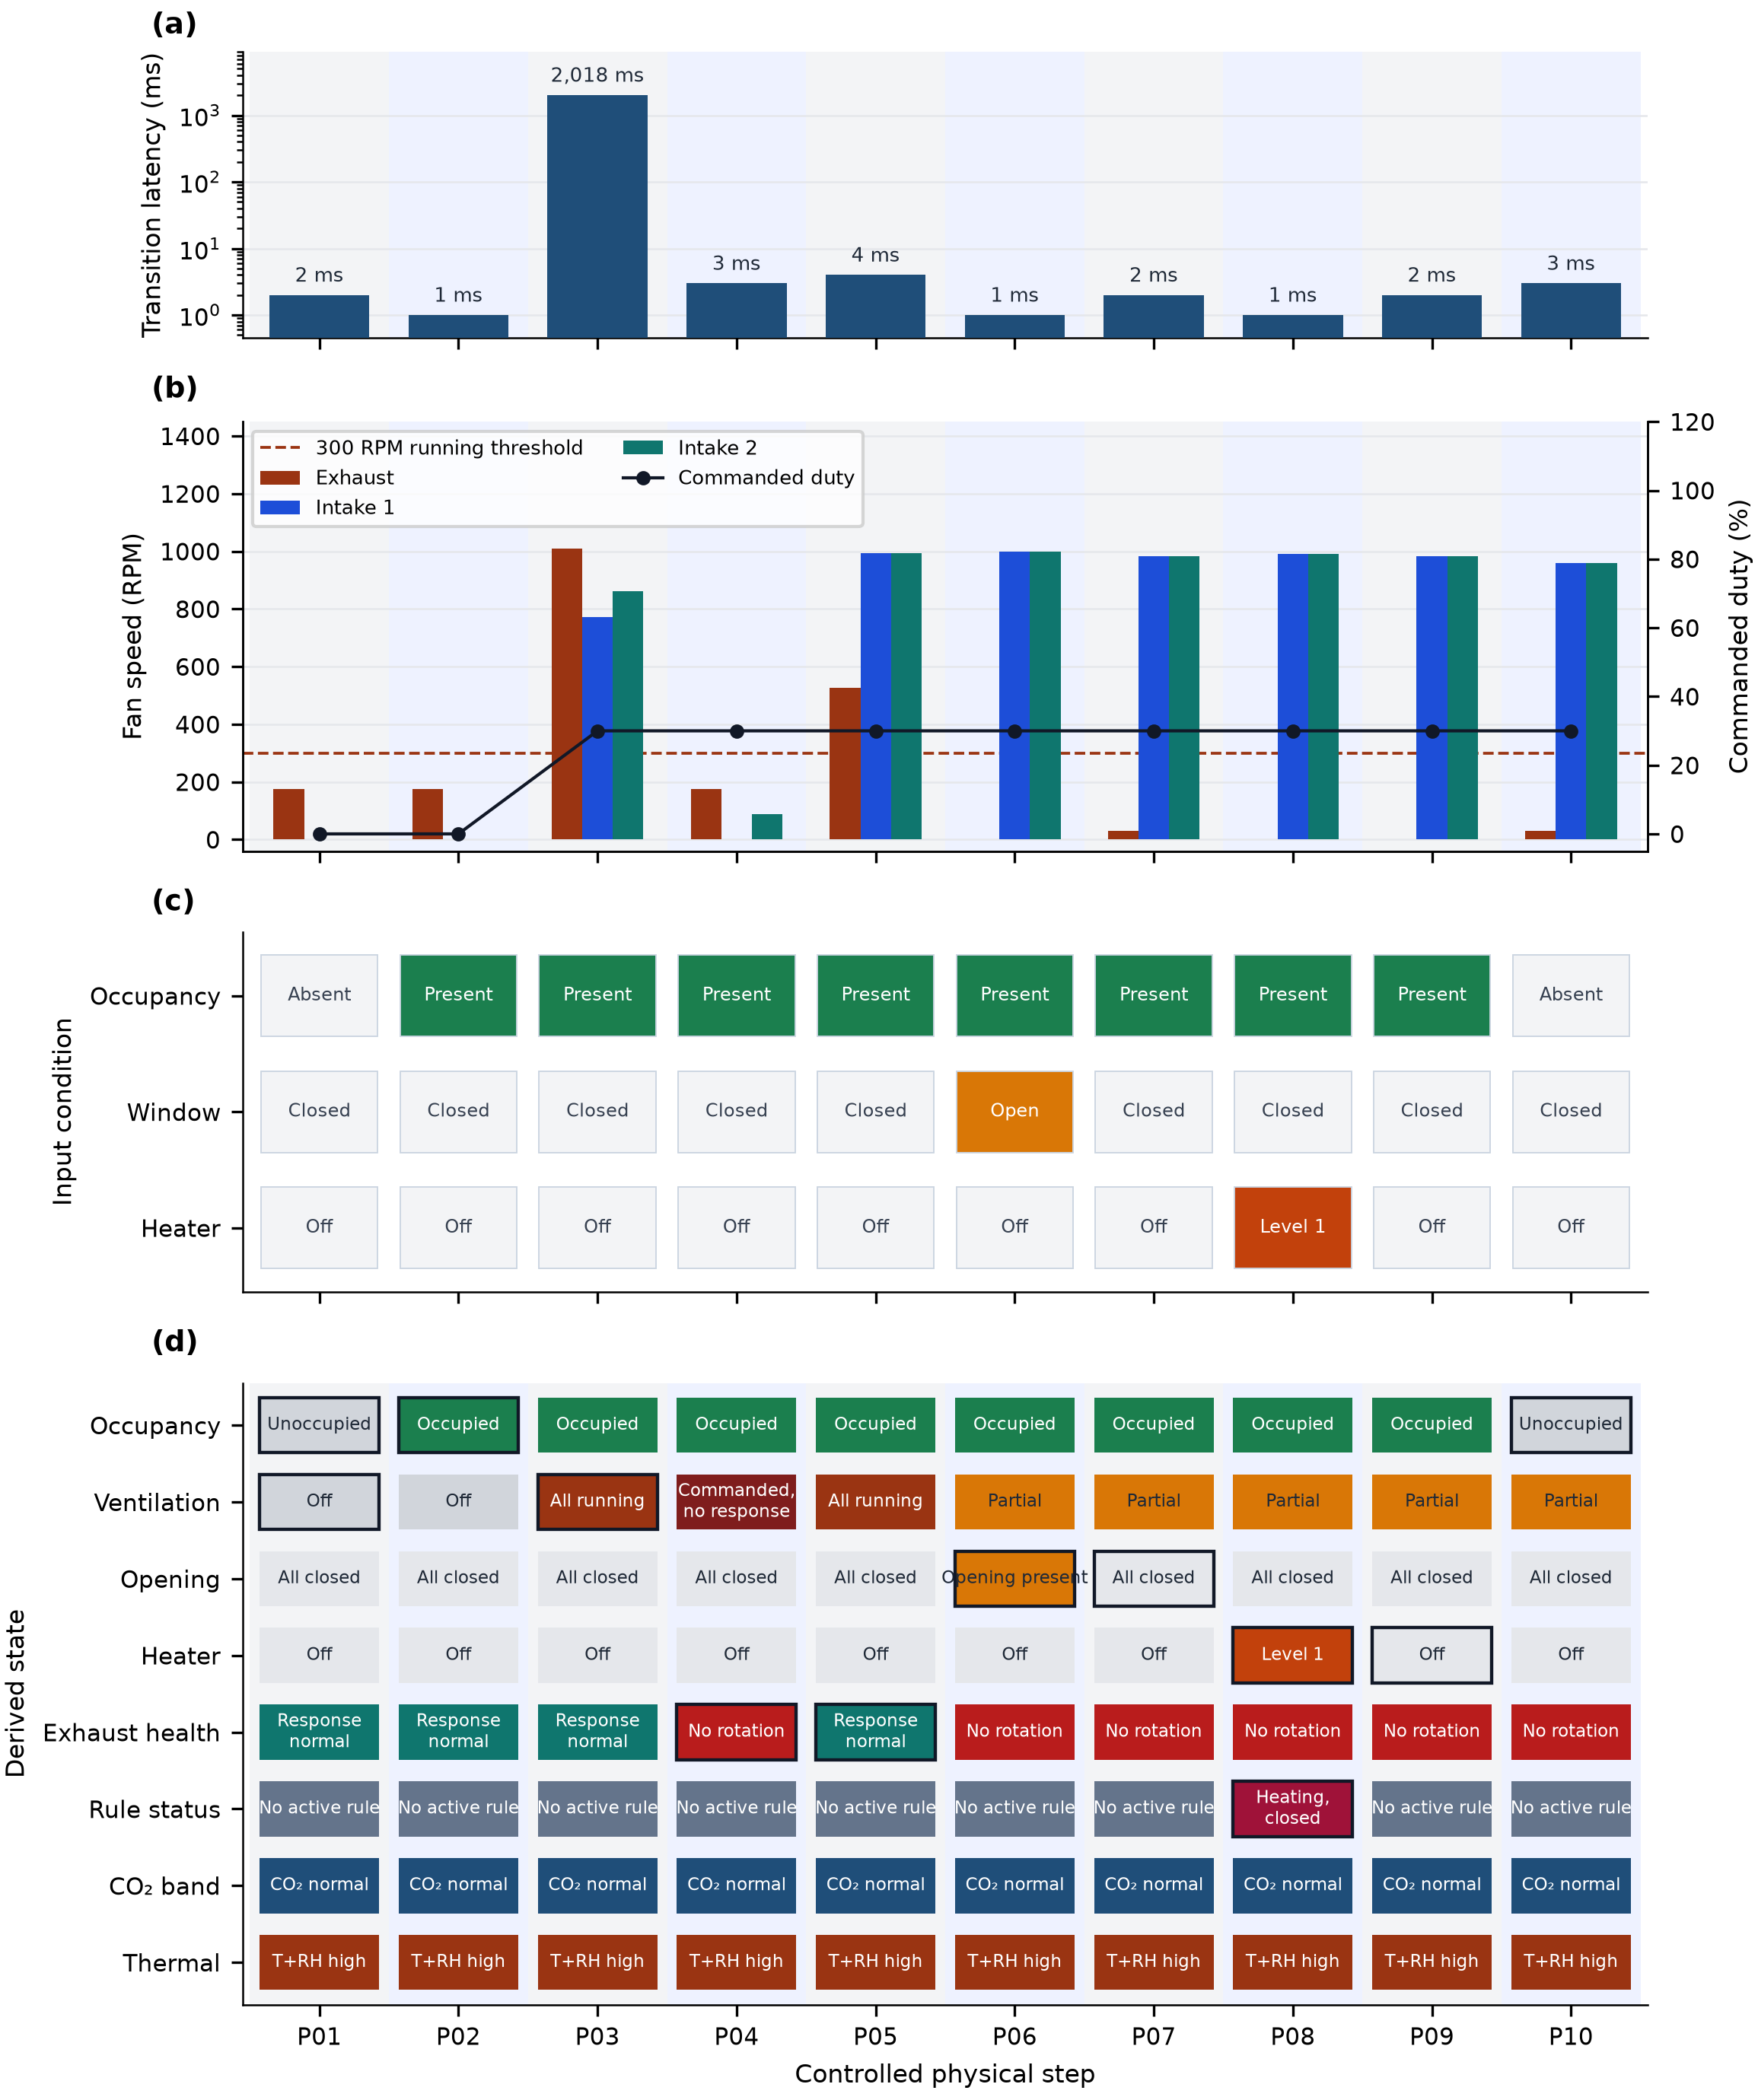

,step,latency_ms,co2_ppm,rpm_exh,rpm_in1,rpm_in2,ROOM01.occupancy_context,ROOM01.ventilation_state,ROOM01.opening_context,ROOM01.heater_context,FAN-EXH.health_context,ROOM01.safety_context
0,P01,2,770.0,174.8,0.0,0.0,UNOCCUPIED,VENTILATION_OFF,ALL_CLOSED,HEATER_OFF,FAN_RESPONSE_NORMAL,NO_RULE_ALERT
1,P02,1,773.0,174.8,0.0,0.0,OCCUPIED,VENTILATION_OFF,ALL_CLOSED,HEATER_OFF,FAN_RESPONSE_NORMAL,NO_RULE_ALERT
2,P03,2018,773.0,1009.9,772.3,861.4,OCCUPIED,VENTILATION_ALL_RUNNING,ALL_CLOSED,HEATER_OFF,FAN_RESPONSE_NORMAL,NO_RULE_ALERT
3,P04,3,765.0,176.6,0.0,88.3,OCCUPIED,VENTILATION_COMMANDED_NO_RESPONSE,ALL_CLOSED,HEATER_OFF,COMMAND_NO_ROTATION,NO_RULE_ALERT
4,P05,4,765.0,526.3,994.2,994.2,OCCUPIED,VENTILATION_ALL_RUNNING,ALL_CLOSED,HEATER_OFF,FAN_RESPONSE_NORMAL,NO_RULE_ALERT
5,P06,1,766.0,0.0,998.0,998.0,OCCUPIED,VENTILATION_PARTIAL,OPENING_PRESENT,HEATER_OFF,COMMAND_NO_ROTATION,NO_RULE_ALERT
6,P07,2,765.0,29.8,982.1,982.1,OCCUPIED,VENTILATION_PARTIAL,ALL_CLOSED,HEATER_OFF,COMMAND_NO_ROTATION,NO_RULE_ALERT
7,P08,1,767.0,0.0,992.2,992.2,OCCUPIED,VENTILATION_PARTIAL,ALL_CLOSED,HEATER_LEVEL1,COMMAND_NO_ROTATION,OCCUPIED_HEATING_CLOSED_ROOM
8,P09,2,769.0,0.0,984.1,984.1,OCCUPIED,VENTILATION_PARTIAL,ALL_CLOSED,HEATER_OFF,COMMAND_NO_ROTATION,NO_RULE_ALERT
9,P10,3,771.0,30.0,960.0,960.0,UNOCCUPIED,VENTILATION_PARTIAL,ALL_CLOSED,HEATER_OFF,COMMAND_NO_ROTATION,NO_RULE_ALERT


In [4]:
display(Image(filename=result["table53_figure"]))
columns = ["step", "latency_ms", "co2_ppm", "rpm_exh", "rpm_in1", "rpm_in2", "ROOM01.occupancy_context", "ROOM01.ventilation_state", "ROOM01.opening_context", "ROOM01.heater_context", "FAN-EXH.health_context", "ROOM01.safety_context"]
display(result["steps"][columns])